# **Assignment 2**


# Preamble

In [1]:
%matplotlib inline

from __future__ import annotations
from abc import ABC, abstractmethod
from dataclasses import dataclass
from functools import partial
from typing import Callable, Optional, Tuple, Dict, Any, List
from tqdm.notebook import tqdm

import csv
import matplotlib.pyplot as plt
import numpy as np

In [2]:
map_metric = {
    "accuracy": "Accuracy",
    "squared_error": "MSE",
}

def mse(X: np.ndarray, Y: np.ndarray, W: np.ndarray) -> float:
    Yhat = X @ W
    err = Yhat - Y
    return 0.5 * np.mean(np.sum(err**2, axis=1))

def set_seed(s: int=0):
    return np.random.default_rng(s)

def lasso(X: np.ndarray, Y: np.ndarray, W: np.ndarray, lam: float) -> float:
    mse_loss = mse(X, Y, W)
    l1_loss = lam * np.sum(np.abs(W))
    return mse_loss + l1_loss

def squared_error(Y_pred: np.array, Y: np.array):
    """ Computes the squared error. """
    if Y.ndim == 1:
        Y = Y[:, None]
    return np.sum(Y_pred - Y, axis=-1) ** 2

def accuracy(Y_pred: np.array, Y: np.array):
    """ Computes the accuracy. """
    return np.sum(Y_pred == Y, axis=-1)

def compute_wilson_ci(n, acc):
    # alpha = 0.05
    acc = np.mean(acc)
    base = (n * acc + 0.5 * 3.841) / (n + 3.841)
    err = np.sqrt(3.841) / (n + 3.841) * np.sqrt(n * acc * (1 - acc) + 0.25 * 3.841)

    return (base - err, base + err)

def compute_normal_ci(n, err):
    # alpha = 0.05
    mean_err = np.mean(err)
    std_err = np.std(err)
    ci = 1.96 * std_err / np.sqrt(n)
    return (mean_err - ci, mean_err + ci)

# Part I: $\ell_1$ vs $\ell_2$ vs unregularized multinomial logistic regression

## Model
`GeneralizedLinearModel` is an abstract base class for generalized linear models that holds a weight matrix `W` of shape `(in_dim, out_dim)` and defines two required behaviours: batch prediction via `predict_batch(X)` and batch gradient computation, the gradient of the loss with respect to `W`, via `grad_batch(X, Y)`.

When we impose a prior on our weights `W`, we get regularization.
In this course we learned about L1 and L2 regularization. You implemented L2 regularization in Assignment 1.
You get to implement L1 regularization for this assignment, Assignment 2.

We assume 
$\mathbf{W} \in\mathbb{R}^{p \times m}$ for feature dimension $p$ and for $m$ classes. 
With a loss function $\ell(\mathbf{x}, \mathbf{y}; \mathbf{W})$ and regularizer $r(\mathbf{W})$, the corresponding regularized problem is:
$$
c_r(\mathbf{x}, \mathbf{y}; \mathbf{W}) = \ell(\mathbf{x}, \mathbf{y}; \mathbf{W}) + \lambda r(\mathbf{W}),
$$
where $\lambda > 0$ is the strength of the regularizer.
We get the $\ell_1$-regularized problem by setting $r(\mathbf{W}) = \lVert \mathbf{W} \rVert_1$:
$$
c_{\ell_1}(\mathbf{x}, \mathbf{y}; \mathbf{W}) = \ell(\mathbf{x}, \mathbf{y}; \mathbf{W}) + \lambda \lVert \mathbf{W} \rVert_1.
$$
For example, we get lasso ($\ell_1$-regularized) regression if $\ell$ is chosen to be the squared error.
Unlike ridge ($\ell_2$-regularized) regression, however, lasso regression has no closed-form solution.
As a result we have to solve iteratively. (Note that for ridge regression we also to solve iteratively with gradient descent, rather than using the closed-form solution, primarily just to get you to start using gradient descent and different optimizers). 

Furthermore, the $\ell_1$ regularizer is non-differentiable at points where weights are 0. 
You will need to fill in the `grad_l1_reg` function that returns the sample subgradient
$$
\nabla_\mathbf{W} \, r(\mathbf{W})
\;\in\;
\operatorname{sign}(\mathbf{W}).
$$
This is called a subgradient because it is not differentiable at 0. The canonical choice for the subgradient at zero is to use a value of zero (rather than say -1 or +1, which is what we get as soon as we move away from zero). In numpy, $\operatorname{sign}(0)$ returns 0.
Note that while we can use gradient descent with this subgradient, it tends to be less effective than using the proximal update. You will also implement the proximal update, and get to see the difference between using the subgradient and the proximal update.

In [3]:
def grad_no_reg(W: np.ndarray) -> np.ndarray:
    """No regularization"""
    return np.zeros_like(W)

def grad_l1_reg(W: np.ndarray) -> np.ndarray:
    """L1 regularization (assumes Laplace prior)"""
    reg = None
    #### BEGIN SOLUTION
    reg = np.copy(W)
    return np.sign(reg)
    #### END SOLUTION
    return reg

def grad_l2_reg(W: np.ndarray) -> np.ndarray:
    """L2 regularization (assumes Gaussian prior)"""
    reg = np.copy(W)
    return reg

In [4]:
REG_TYPES = [grad_no_reg, grad_l1_reg, grad_l2_reg]

class Model:
    """
    Abstract base class for generalized linear models with weight matrix W (p x m).

    Args:
        in_dim (int): Number of input features p (assumes user has included a 1 feature in x if a bias unit is desired).
        out_dim (int): Number of outputs/classes m. Defaults to 1.
        grad_regularizer (callable): The gradient of the regularizer being used.
        lambda_ (float): The regularization coefficient (penalty strength) λ.
        penalize_bias (bool): Whether to apply the L2 penalty to the bias column of W.
    """
    def __init__(self,
                 in_dim: int,
                 out_dim: int = 1,
                 grad_regularizer: callable=grad_no_reg,
                 lambda_: float = 0.0,
                 penalize_bias: bool = True):
        assert in_dim > 0, "in_dim must be positive, got {}".format(in_dim)
        assert out_dim > 0, "out_dim must be positive, got {}".format(out_dim)
        assert grad_regularizer in REG_TYPES, "reg_type must be one of {}".format(
            REG_TYPES
        )
        assert lambda_ >= 0.0, "lambda_ must be positive, got {}".format(
            lambda_
        )
        self.in_dim = int(in_dim)
        self.out_dim = int(out_dim)
        self.W = np.zeros((in_dim, out_dim), dtype=float)
        self.grad_regularizer = grad_regularizer
        self.lambda_ = float(lambda_)
        self.penalize_bias = bool(penalize_bias)

    def predict_batch(self,
                      X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def grad_batch_without_reg(self,
                               X: np.array,
                               Y: np.array) -> np.ndarray:
        raise NotImplementedError

    def grad_batch(self,
                   X: np.ndarray,
                   Y: np.ndarray) -> np.ndarray:
        loss_G = self.grad_batch_without_reg(X, Y)
        reg_G = self.grad_regularizer(self.W)

        # Optionally exclude bias row from penalty (assumes bias is first row in W)
        if not self.penalize_bias:
            reg_G[0, :] = 0.0

        return loss_G + self.lambda_ * reg_G

In [5]:
class GaussianGLM(Model):
    """
    Assumes that p(y|x) is a Gaussian, or equivalently, a standard linear regression model.
    """

    def predict_batch(self,
                      X: np.ndarray) -> np.ndarray:
        # Forward pass: matrix multiply features by weights -> predictions (n×m)
        pred = X @ self.W
        return pred

    def grad_batch_without_reg(self,
                               X: np.ndarray,
                               Y: np.ndarray) -> np.ndarray:
        # Ensure targets are 2D (n×m) to match predictions' shape
        Y = Y.reshape(-1, 1) if Y.ndim == 1 else Y
        # Residuals: prediction error (n×m)
        err = X @ self.W - Y
        # Mean gradient over the batch: Xᵀ err / n  (shape d×c)
        G = (X.T @ err) / X.shape[0]
        return G


In [6]:
# ----- Lasso Tests (batch versions) -----
def test_grad_mse_part_only():
    rng = set_seed(42)
    n, p, m = 7, 5, 2
    X = rng.normal(size=(n, p))
    W = rng.normal(size=(p, m))
    Y = rng.normal(size=(n, m))
    model = GaussianGLM(in_dim=p,
                        out_dim=m,
                        grad_regularizer=grad_l1_reg,
                        lambda_=0.0)
    model.W = W.copy()
    G = model.grad_batch(X, Y)
    expected = (X.T @ (X @ W - Y)) / n
    assert G.shape == (p, m)
    assert np.allclose(G, expected, atol=1e-8)

def test_grad_l1_term_only():
    p, m = 4, 3
    X = np.zeros((6, p))
    Y = np.zeros((6, m))
    lam = 1e-3
    model = GaussianGLM(in_dim=p,
                        out_dim=m,
                        grad_regularizer=grad_l1_reg,
                        lambda_=lam,
                        penalize_bias=True)
    model.W = np.array([[ 1.0, -2.0,  0.5],
                        [-3.0,  4.0, -0.7],
                        [ 2.5, -1.1,  0.9],
                        [-0.2,  0.3, -5.0]])
    G = model.grad_batch(X, Y)
    expected = lam * np.sign(model.W)
    assert np.allclose(G, expected, atol=0)

def test_grad_l1_term_only_no_bias():
    p, m = 4, 3
    X = np.zeros((6, p))
    Y = np.zeros((6, m))
    lam = 1e-3
    model = GaussianGLM(in_dim=p,
                        out_dim=m,
                        grad_regularizer=grad_l1_reg,
                        lambda_=lam,
                        penalize_bias=False)
    model.W = np.array([[ 1.0, -2.0,  0.5],
                        [-3.0,  4.0, -0.7],
                        [ 2.5, -1.1,  0.9],
                        [-0.2,  0.3, -5.0]])
    G = model.grad_batch(X, Y)
    expected = lam * np.sign(model.W)
    expected[0] = 0
    assert np.allclose(G, expected, atol=0)

def test_grad_finite_difference():
    rng = set_seed(7)
    n, p, m = 8, 6, 2
    X = rng.normal(size=(n, p))
    W = rng.normal(size=(p, m)) + 0.1
    Y = rng.normal(size=(n, m))
    lam = 5e-4
    model = GaussianGLM(in_dim=p,
                        out_dim=m,
                        grad_regularizer=grad_l1_reg,
                        lambda_=lam,
                        penalize_bias=True)
    model.W = W.copy()
    G = model.grad_batch(X, Y)
    eps = 1e-6
    coords = [(0, 0), (p-1, m-1), (3, 1)]
    for i, j in coords:
        Wp = W.copy(); Wp[i, j] += eps
        Wm = W.copy(); Wm[i, j] -= eps
        Lp = lasso(X, Y, Wp, lam)
        Lm = lasso(X, Y, Wm, lam)
        numgrad = (Lp - Lm) / (2 * eps)
        assert np.isclose(numgrad, G[i, j], rtol=1e-4, atol=1e-6)

test_grad_mse_part_only()
test_grad_l1_term_only()
test_grad_l1_term_only_no_bias()
test_grad_finite_difference()
print("All Lasso tests passed ✅")


All Lasso tests passed ✅


## Optimizer

`Optimizer` is a class that performs in-place parameter updates on a model at each training step. It exposes a single method `step(model, X, Y)`, which (1) computes the gradient `g = model.grad_batch(X, Y)` implemented by the model, and (2) updates the model’s parameters `model.W` accordingly.

In [7]:
class Optimizer:
    """Abstract batch optimizer API."""
    def step(self,
             model: Model,
             X: np.ndarray,
             Y: np.ndarray):
        raise NotImplementedError

class SGD(Optimizer):
    """
    Mini-batch stochastic gradient descent with a fixed step size η.

    Args:
        eta (float): Fixed step size of SGD, η.
    """
    def __init__(self,
                 eta: float = 1e-2):
        self.eta = float(eta)

    def step(self,
             model: Model,
             X: np.ndarray,
             Y: np.ndarray):
        # Compute batch gradient of the loss w.r.t. parameters (shape matches W: p x m)
        G = model.grad_batch(X, Y)
        # Gradient step: W ← W − η G
        model.W -= self.eta * G

### Proximal gradient descent (PGD)

With a differentiable cost function $\ell(\mathbf{x}, \mathbf{y}; \mathbf{W})$ and a non-differentiable regularizer $r(\mathbf{W})$, one way to update the parameters is to use proximal gradient descent (PGD).
Recall that the proximal gradient updates take the form
\begin{align*}
\tilde{\mathbf{W}}_{t + 1} &\gets \mathbf{W}_t - \eta_t \nabla_{\mathbf{W}} \ell(\mathbf{x}, \mathbf{y}; \mathbf{W})\\
\mathbf{W}_{t + 1} &\gets \mathrm{prox}_{\eta_t r}(\tilde{\mathbf{W}}_{t + 1}),
\end{align*}
where $\eta_t > 0$ is the step size at time step $t$, the first line is the gradient step (on the smoothed component), and the second line is the projection step.
The RHS of the second step is called the *proximal operator*, written as
$$
\mathrm{prox}_{\eta_t r}(\tilde{\mathbf{W}}_{t + 1}) := \arg\min_{\mathbf{W}} \frac{1}{2} \lVert \mathbf{W} - \tilde{\mathbf{W}}_{t + 1} \rVert_F^2 + \eta_t r(\mathbf{W}).
$$

With the $\ell_1$-regularizer with regularization parameter $\lambda$, we set $r = \lambda \ell_1$ and the corresponding proximal operator is
$$
\mathrm{prox}_{\eta \lambda \ell_1}(w_{ij}) = \begin{cases}
    w_{ij} - \eta \lambda & \text{if }w_{ij} > \eta \lambda\\
    0  & \text{if } \lvert w_{ij} \rvert \leq \eta \lambda\\
    w_{ij} + \eta \lambda & \text{if }w_{ij} < -\eta \lambda\\
\end{cases}.
$$

In [8]:
def l1_prox_op(W: np.ndarray, lambda_: float, eta: float) -> np.ndarray:
    """
    The proximal operator for l1 regularizer.

    Args:
        W (np.ndarray): The parameters to project.
        lambda_ (float): The regularization coefficient (penalty strength) λ.
        eta (float): Fixed step size of PGD, η.
    """
    proj_W = np.zeros_like(W)

    #### BEGIN SOLUTION
    nl = eta * lambda_
    proj_W = np.sign(W) * np.maximum(np.abs(W) - nl, 0)
    #### END SOLUTION

    return proj_W

In [9]:
PROXIMAL_OPERATORS = [l1_prox_op]

class PGD(Optimizer):
    """
    Mini-batch proximal gradient descent with a fixed step size η.
    NOTE: Assumes that the regularization parameter λ resides in the model.

    Args:
        eta (float): Fixed step size of PGD, η.
        prox_op (callable): The proximal operator to use.
    """
    def __init__(self,
                 eta: float = 1e-2,
                 prox_op: callable=l1_prox_op):
        assert prox_op in PROXIMAL_OPERATORS, "prox_op must be one of {}".format(
            PROXIMAL_OPERATORS
        )
        self.eta = float(eta)
        self.prox_op = prox_op

    def step(self,
             model: Model,
             X: np.ndarray,
             Y: np.ndarray):
        #### BEGIN SOLUTION
        grad = model.grad_batch_without_reg(X, Y)
        W_new = model.W - self.eta * grad
        model.W = self.prox_op(W_new, model.lambda_, self.eta)
        #### END SOLUTION

In [10]:
print("== Testing L1 proximal operator ==")

# 1) m = 1
eta = 0.1
lambda_ = 0.1
threshold = eta * lambda_
W = np.array([[1],
              [-1],
              [0.01],
              [0.001],])
expected_W = np.array([[1 - threshold],
                       [-1 + threshold],
                       [0.01 - threshold],
                       [0.0],])
new_W = l1_prox_op(W, lambda_, eta)
assert np.allclose(new_W, expected_W)

# 2) m = 2
eta = 0.1
lambda_ = 0.1
threshold = eta * lambda_
W = np.array([[1, 2],
              [-1, -2],
              [0.01, -0.01],
              [0.001, -0.001],])
expected_W = np.array([[1 - threshold, 2 - threshold],
                       [-1 + threshold, -2 + threshold],
                       [0.01 - threshold, -0.01 + threshold],
                       [0.0, 0.0],])
new_W = l1_prox_op(W, lambda_, eta)
assert np.allclose(new_W, expected_W)
print("✅ All L1 proximal operator tests passed!")

== Testing L1 proximal operator ==
✅ All L1 proximal operator tests passed!


In [11]:
print("== Testing PGD (batch) ==")

# 1) Single step equals W - η * grad
p, m = 4, 1
eta = 1e-2
lambda_ = 1e-2
pgd = PGD(eta)
model = GaussianGLM(p, m, grad_l1_reg, lambda_)
model.W = np.array([[0.5],[-0.2],[0.1],[1.0]])
Xb = np.array([[1.0,-2.0,0.5,3.0]])
yb = np.array([[0.4]])
G = model.grad_batch_without_reg(Xb, yb).copy()
sgd_weight = model.W - eta * G
expected_weight = l1_prox_op(sgd_weight, lambda_, eta)
pgd.step(model, Xb, yb)
assert np.allclose(model.W, expected_weight)

# 2) few steps reduce loss and has zero weight on some features
rng = np.random.default_rng(0)
p, m = 5, 1
lambda_ = 5e-1
pgd = PGD(eta=5e-2)
model = GaussianGLM(p, m, grad_l1_reg, lambda_)
X = rng.normal(size=(50, p))
W_true = rng.normal(size=(p, m))
W_true[:2] = 0.0
Y = X @ W_true
loss0 = mse(X, Y, model.W)
for _ in range(3):
    pgd.step(model, X, Y)
loss1 = mse(X, Y, model.W)
assert loss1 < loss0
assert np.allclose(model.W[:2], 0.0)
print("✅ All PGD tests passed!")


== Testing PGD (batch) ==
✅ All PGD tests passed!


<!-- # Part II: Multinomial logistic regression and model selection -->

## Softmax

Softmax maps a vector of real-valued logits to a probability distribution over $m$ classes by exponentiating and normalizing each component. For a sample $i$ with logits $\mathbf z_i = \boldsymbol{\phi}_i \mathbf{W} \in\mathbb R^{m}$, the probability of class $j \in \{1, 2, \dots, m\}$ is
$$
\mathrm{softmax}(\mathbf z_i)_j = p_{i, j}=\frac{\exp(z_{i, j})}{\sum_{k=1}^{m}\exp(z_{i,k})}.
$$

The naive computation is prone to numerical instability when some $z_{ij}$ is sufficiently large (prone to overflow).
As a result we compute $\mathrm{softmax}(\mathbf z_i)$ using
$$
\frac{\exp\!\big(\mathbf z_i-\max(\mathbf z_i)\big)}{\sum_{k=1}^{m}\exp\!\big(z_{i,k}-\max(\mathbf z_i)\big)}.
$$
This called the max normalization trick. We can do this shift because this constant $\exp(\max(\mathbf z_i))$ factors out from both the numerator and denominator, cancelling out and giving back the exact same softmax formula. You can check this for yourself. 


In [12]:
def softmax(Z: np.ndarray) -> np.ndarray:
    """
    Numerically stable row-wise softmax.

    Args:
        Z (np.ndarray): The logits.
    """
    dist = None
    Z = Z - Z.max(axis=1, keepdims=True)
    #### BEGIN SOLUTION
    expZ = np.exp(Z)
    dist = expZ / expZ.sum(axis=1, keepdims=True)
    #### END SOLUTION
    return dist

In [13]:
print("== Testing softmax ==")
def softmax_axis(Z: np.ndarray, axis: int = -1) -> np.ndarray:
    Z = np.asarray(Z, dtype=float)
    maxZ = np.max(Z, axis=axis, keepdims=True)
    expZ = np.exp(Z - maxZ)
    return expZ / np.sum(expZ, axis=axis, keepdims=True)

# Softmax tests
def test_rows_sum_to_one():
    rng = np.random.default_rng(0)
    Z = rng.normal(size=(5, 7))
    P = softmax_axis(Z, axis=1)
    assert P.shape == Z.shape
    s = P.sum(axis=1)
    assert np.allclose(s, 1.0, atol=1e-12)

def test_translation_invariance():
    rng = np.random.default_rng(1)
    Z = rng.normal(size=(4, 3))
    c = rng.normal(size=(4, 1))
    P1 = softmax_axis(Z, axis=1)
    P2 = softmax_axis(Z + c, axis=1)
    assert np.allclose(P1, P2, atol=1e-12)

def test_numerical_stability_large_logits():
    Z = np.array([[1000.0, 999.0, 990.0],
                  [-1000.0, -1001.0, -1010.0]])
    P = softmax_axis(Z, axis=1)
    assert np.all(np.isfinite(P))
    assert np.allclose(P.sum(axis=1), 1.0, atol=1e-12)
    assert np.argmax(P[0]) == 0

test_rows_sum_to_one()
test_translation_invariance()
test_numerical_stability_large_logits()
print("✅ All softmax tests passed")


== Testing softmax ==
✅ All softmax tests passed


## Multinomial logistic regression (Softmax)

In multinomial logistic regression, we aim to learn $p(\mathbf{y} | \mathbf{x})$ where $\mathbf{y} \in \{0,1\}^m$ is a one-hot vector encoding the class for input $\mathbf{x}$. For example, for $\mathbf{y} = [y_1, y_2, \ldots, y_m]$, if the class for $\mathbf{x}$ is class j, then $y_j = 1$ and the rest are zero.
We parameterize this distribution using the *softmax* transfer, 
$$
\mathrm{softmax}(\phi(\mathbf{x}) \mathbf{W}) = \left[ \frac{\exp \left( \phi(\mathbf{x}) \mathbf{w}_1 \right)}{\sum_{j=1}^m \exp \left( \phi(\mathbf{x}) \mathbf{w}_j \right)}, \dots, \frac{\exp \left( \phi(\mathbf{x}) \mathbf{w}_m \right)}{\sum_{j=1}^m \exp \left( \phi(\mathbf{x}) \mathbf{w}_j \right)}  \right].
$$

By taking the negative log likelihood, we obtain the cross-entropy loss
$$
\ell(\mathbf{x}, \mathbf{y}; \mathbf{W}) = -\sum_{j=1}^m y_j \log p_{j},
$$
where $p_j = \mathrm{softmax}(\phi(\mathbf{x}) \mathbf{W})_j$ is the probability of class $j$ given input $\mathbf{x}$.

The corresponding gradient is
$$
\nabla_\mathbf{W} \ell(\mathbf{x}, \mathbf{y}; \mathbf{W}) = \phi(\mathbf{x})^\top(\mathrm{softmax}(\phi(\mathbf{x}) \mathbf{W}) - y).
$$

In [14]:
class MultinomialLogisticGLM(Model):
    """
    Assumes that p(y|x) is a multinomial, or equivalently, a multinomial logistic regression.
    The transfer function in this case is the softmax transfer.
    """

    def predict_batch(self,
                      X: np.ndarray) -> np.ndarray:
        # Forward pass: matrix multiply features by weights -> predictions (n×m)
        probs = softmax(X @ self.W)
        pred = probs.argmax(axis=1, keepdims=True)
        return pred

    def grad_batch_without_reg(self,
                               X: np.ndarray,
                               Y: np.ndarray) -> np.ndarray:
        G = None
        #### BEGIN SOLUTION
        n = X.shape[0]
        probs = softmax(X @ self.W)
    
        Y_onehot = np.zeros_like(probs)
        Y_onehot[np.arange(n), Y] = 1.0
    
        G = (X.T @ (probs - Y_onehot)) / n
        #### END SOLUTION
        return G


In [15]:
print("== Testing MultinomialLogisticGLM ==")

def _avg_nll_with_ridge(Z, W, y, lam):
    logits = Z @ W
    m = logits.max(axis=1, keepdims=True)
    logsumexp = m + np.log(np.exp(logits - m).sum(axis=1, keepdims=True))
    log_probs = logits - logsumexp
    nll = -log_probs[np.arange(len(y)), y.astype(int)].mean()
    ridge = 0.5 * lam * (W * W).sum()
    return nll + ridge

def test_multinomial():
    rng = np.random.default_rng(0)
    n, p, m = 16, 7, 5
    model = MultinomialLogisticGLM(in_dim=p, out_dim=m)
    X = rng.normal(size=(n, p))
    y = rng.integers(0, m, size=n)
    model.W = rng.normal(size=(p, m))
    Z = X
    P = softmax(Z @ model.W)
    Y = np.zeros_like(P); Y[np.arange(n), y] = 1.0
    expected = (Z.T @ (P - Y)) / n
    G = model.grad_batch(X, y)
    assert G.shape == (p, m)
    assert np.allclose(G, expected, rtol=1e-10, atol=1e-12)

def test_multinomial_l2():
    rng = np.random.default_rng(1)
    n, p, m = 20, 6, 4
    lam = 1e-3
    model = MultinomialLogisticGLM(in_dim=p,
                                   out_dim=m,
                                   grad_regularizer=grad_l2_reg,
                                   lambda_=lam)
    X = rng.normal(size=(n, p))
    y = rng.integers(0, m, size=n)
    model.W = rng.normal(size=(p, m))
    Z = X
    P = softmax(Z @ model.W)
    Y = np.zeros_like(P); Y[np.arange(n), y] = 1
    data_grad = (Z.T @ (P - Y)) / n
    expected = data_grad + lam * model.W
    G = model.grad_batch(X, y)

    assert np.allclose(G, expected, rtol=1e-10, atol=1e-12)

def test_multinomial_l2_finite_difference():
    rng = np.random.default_rng(2)
    n, p, m = 12, 5, 3
    lam = 2e-3
    model = MultinomialLogisticGLM(in_dim=p,
                                   out_dim=m,
                                   grad_regularizer=grad_l2_reg,
                                   lambda_=lam)
    X = rng.normal(size=(n, p))
    y = rng.integers(0, m, size=n)
    W = rng.normal(size=(p, m))
    model.W = W.copy()
    G = model.grad_batch(X, y)
    Z = X
    eps = 1e-6
    coords = [(0, 0), (p-1, m-1), (2, 1)]
    for (i, j) in coords:
        Wp = W.copy(); Wp[i, j] += eps
        Wm = W.copy(); Wm[i, j] -= eps
        Lp = _avg_nll_with_ridge(Z, Wp, y, lam)
        Lm = _avg_nll_with_ridge(Z, Wm, y, lam)
        numgrad = (Lp - Lm) / (2 * eps)
        assert np.isclose(numgrad, G[i, j], rtol=5e-4, atol=1e-6)

def test_multinomial_l1():
    rng = np.random.default_rng(1)
    n, p, m = 20, 6, 4
    lam = 1e-3
    model = MultinomialLogisticGLM(in_dim=p,
                                   out_dim=m,
                                   grad_regularizer=grad_l1_reg,
                                   lambda_=lam)
    X = rng.normal(size=(n, p))
    y = rng.integers(0, m, size=n)
    model.W = rng.normal(size=(p, m))
    Z = X
    P = softmax(Z @ model.W)
    Y = np.zeros_like(P); Y[np.arange(n), y] = 1
    data_grad = (Z.T @ (P - Y)) / n
    expected = data_grad + lam * np.sign(model.W)
    G = model.grad_batch(X, y)

    assert np.allclose(G, expected, rtol=1e-10, atol=1e-12)

test_multinomial()
test_multinomial_l2()
test_multinomial_l2_finite_difference()
test_multinomial_l1()
print("✅ All MultinomialLogisticGLM tests passed")


== Testing MultinomialLogisticGLM ==
✅ All MultinomialLogisticGLM tests passed


## Trainer

`Trainer` runs the outer training loop so your models and optimizers can stay minimal.
It handles epoching, mini-batches of batch size $b > 0$, shuffling with a fixed seed for reproducibility, and metric tracking.
Here, one epoch corresponds to completely iterating through the dataset of size $n$ once.

On each epoch, the trainer first permutes the $N$ samples and iterates over mini-batches of size $M$, i.e., iterating $\ell = \lfloor \frac{n}{b} \rfloor$ mini-batches, dropping the last mini-batch when $M$ does not divide $N$.
On the $i$'th mini-batch, `(X_i, Y_i)`, the trainer updates the model parameters `model.W` by calling `optimizer.step(model, X_i, Y_i)`.
At the end of each epoch, the trainer computes and logs the metric on the training set---and on the validation set when `X_val` and `Y_val` are provided---under `history["train_metric"]` and `history["metric"]`.
Here, the metric is not yet aggregated, so `history[key]` is a list of $n$-dimensional vector, where the $i$'th entry corresponds to the metric evaluated on the $i$'th sample.

To use it, provide any `Model` with `predict_batch(X)` and `grad_batch(X, Y)` plus an `Optimizer` with `step(model, X, Y)`.
`Trainer` keeps the roles cleanly separated: models define predictions and gradients; optimizers define the update rule (e.g., SGD); and the trainer orchestrates data flow, randomness, and evaluation so that runs with the same initialization and seed produce identical learning behavior.

In [16]:
class Trainer:
    """
    Mini-batch training loop that logs per epoch (optionally on a validation set).

    Args:
        model (Model): The particular model to use.
        optimizer (Optimizer): The optimizer to use.
        metric (callable): The metric to use to keep track of model performance.
        epochs (int): Number of epochs to train.
        batch_size (int): Number of samples per mini-batch.
        shuffle (bool): Whether to shuffle the data.
        seed (int): Random seed.
    """
    def __init__(self,
                 model: Model,
                 optimizer: Optimizer,
                 metric: callable,
                 epochs: int = 100,
                 batch_size: int = 32,
                 shuffle: bool = True,
                 seed: int = 0):
        self.model = model
        self.optimizer = optimizer
        self.metric = metric
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.seed = int(seed)
        self.history = {
            "train_metric": [],
            "val_metric": [],
        } # Per-epoch metrics for plotting

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,
            X_val: Optional[np.ndarray] = None,
            Y_val: Optional[np.ndarray] = None):
        rng = np.random.default_rng(self.seed)
        n = len(Y)
        B = self.batch_size
        for _ in range(self.epochs):
            # Shuffle once per epoch
            idx = rng.permutation(n) if self.shuffle else np.arange(n)

            # Iterate over mini-batches
            for s in range(0, n, B):
                batch_idx = idx[s:s+B]
                Xb, Yb = X[batch_idx], Y[batch_idx]
                # One optimizer step per batch
                self.optimizer.step(self.model, Xb, Yb)

            # Track training metric (and validation) after the epoch
            train_metric = self.metric(self.model.predict_batch(X), Y)
            self.history["train_metric"].append(train_metric)
            if X_val is not None and Y_val is not None:
                val_metric = self.metric(self.model.predict_batch(X_val), Y_val)
                self.history["val_metric"].append(val_metric)
        return self


## Experiments

In [17]:
def create_dataset(seed=42,
                   n_train=200,
                   n_val=200,
                   p=100,
                   k=5,
                   m=3,
                   noise=0.1,):
    rng = np.random.default_rng(seed)
    n = n_train + n_val
    n_per_class = [int(np.floor(n / m))] * m
    if n % m > 0:
        n_per_class[-1] += n % m

    w_true = np.zeros((p, m))
    w_true[m + 1] = np.ones(m) * 1.0
    w_true[:k] = w_true[:k] + np.eye(k)[:, :m] * 0.1 + rng.normal(0.0, 0.01, size=(k, m))

    # Correlated columns
    X_all = np.concatenate([
        np.eye(k)[class_i][None] * 0.5 + rng.normal(0.0, 0.01, size=(n_per_class[class_i], k))
        for class_i in range(m)
    ], axis=0)
    X_all = np.concatenate((X_all, rng.normal(0.0, 0.1, size=(n, p - k))), axis=1)
    perm_idxes = rng.permutation(n)
    X_all = X_all[perm_idxes]

    def dup_X(X):
        n = len(X)
        n_per_class = [int(np.floor(n / m))] * m
        if n % m > 0:
            n_per_class[-1] += n % m
        for j in range(m):
            base = j
            start_samples_idx = j * n_per_class[j]
            end_samples_idx = min(start_samples_idx + int(n_per_class[j] * 0.5), n)

            for dup_i in range(1, p // k):
                dup = dup_i * k + j
                X[start_samples_idx:end_samples_idx, dup] = X[
                    start_samples_idx:end_samples_idx, base
                ] + (2 ** -dup_i) * rng.normal(size=(end_samples_idx - start_samples_idx,))

        return X
    X_all[:] = dup_X(X_all[:])

    # Standardize
    X_all = (X_all - X_all.mean(axis=0, keepdims=True)) / (X_all.std(axis=0, keepdims=True) + 1e-8)

    # Prediction
    y_all = X_all @ w_true + noise * rng.normal(size=(n, m))
    y_all = np.argmax(y_all, axis=-1, keepdims=True)

    X_tr, X_val = X_all[:n_train], X_all[n_train:]
    y_tr, y_val = y_all[:n_train], y_all[n_train:]

    return (X_tr, y_tr, X_val, y_val)

seed = 3
p = 500
k = 5
m = 3
X_tr, y_tr, X_val, y_val = create_dataset(seed=seed, p=p, k=k, m=m)

lams = 10.0 ** np.arange(-5, 2)
tau = 1e-4

nonzero_pct = dict()
val_acc = dict()
val_acc_se = dict()

lr = 0.3
epochs = 200
batch_size = 128

for (exp_name, opt_constructor, grad_regularizer) in (
    ("$\\ell_1$ PGD", PGD, grad_l1_reg),
    ("$\\ell_1$ SGD", SGD, grad_l1_reg),
    ("$\\ell_2$ SGD", SGD, grad_l2_reg),
    ("No reg. SGD", SGD, grad_no_reg),
):
    nonzero_pct.setdefault(exp_name, [])
    val_acc.setdefault(exp_name, [])
    val_acc_se.setdefault(exp_name, [])
    for lam in lams:
        model = MultinomialLogisticGLM(
            in_dim=p,
            out_dim=m,
            grad_regularizer=grad_regularizer,
            lambda_=lam,
            penalize_bias=True,
        )
        opt = opt_constructor(lr)
        trainer = Trainer(model=model,
                          optimizer=opt,
                          metric=accuracy,
                          epochs=epochs,
                          batch_size=batch_size,
                          seed=seed,)
        trainer.fit(X_tr, y_tr, X_val=X_val, Y_val=y_val)

        val_acc[exp_name].append(np.mean(trainer.history["val_metric"][-1]))
        val_acc_se[exp_name].append(
            compute_wilson_ci(len(trainer.history["val_metric"][-1]), trainer.history["val_metric"][-1])
        )
        nonzero_pct[exp_name].append(100 * np.mean(np.abs(model.W) > tau))

        if exp_name == "No reg. SGD":
            break

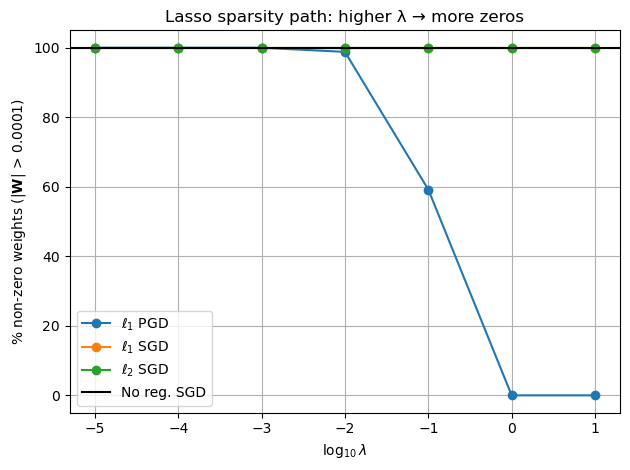

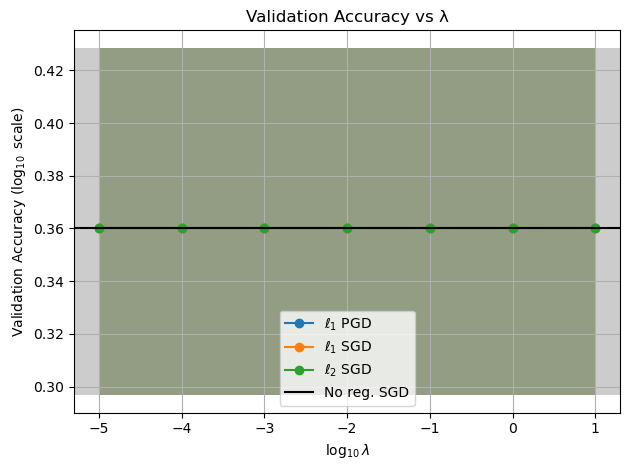

In [36]:
plt.figure()
for key in nonzero_pct:
    if key == "No reg. SGD":
        plt.axhline(nonzero_pct[key][0], label=key, color="black")
    else:
        plt.plot(np.log10(lams), nonzero_pct[key], marker="o", label=key)
plt.xlabel("$\\log_{10} \\lambda$")
plt.ylabel("% non-zero weights ($|\\mathbf{{ W }}|$ > {})".format(tau))
plt.title("Lasso sparsity path: higher λ → more zeros")
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.savefig("figure1.png")
plt.show()

plt.figure()
for key in val_acc:
    mean = np.array(val_acc[key])
    # std_err = 1.96 * np.array(val_acc_se[key])
    std_err = np.array(val_acc_se[key])
    if key == "No reg. SGD":
        plt.axhline((mean[0]),
                    label=key,
                    color="black")
        plt.axhspan((std_err[0, 0]),
                    (std_err[0, 1]),
                    facecolor="black",
                    alpha=0.2)
    else:
        plt.plot(np.log10(lams),
                 (mean),
                 marker="o",
                 label=key)
        plt.fill_between(np.log10(lams),
                         std_err[:, 0],
                         std_err[:, 1],
                         alpha=0.2)

plt.xlabel("$\\log_{10} \\lambda$")
plt.ylabel("Validation {} ($\\log_{{10}}$ scale)".format(map_metric[accuracy.__name__]))
plt.title("Validation {} vs λ".format(map_metric[accuracy.__name__]))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("figure2.png")
plt.show()


# Part II: Model selection

## Fixed Representation

This abstract class defines the contract for fixed representations.
Subclasses must implement (i) `fit(X)` to learn or select any internal parameters (e.g., prototype centers) from data and return `self`, and (ii) `transform(X)` to map inputs into a feature matrix.

Recall that a feature matrix is
$$
\mathbf{\Phi} = \begin{bmatrix}
  \phi_0(\mathbf{x}_1) & \phi_1(\mathbf{x}_1) & \dots & \phi_p(\mathbf{x}_1)\\
  \phi_0(\mathbf{x}_2) & \phi_1(\mathbf{x}_2) & \dots & \phi_p(\mathbf{x}_2)\\
  \vdots & \vdots & \ddots & \vdots \\
  \phi_0(\mathbf{x}_n) & \phi_1(\mathbf{x}_n) & \dots & \phi_p(\mathbf{x}_n)\\
\end{bmatrix},
$$
where $\phi_0(\mathbf{x}) = 1$ is the bias term, and $\phi_j(\mathbf{x}) \in \mathbb{R}$ is the $j$'th feature mapping.

In [19]:
class FixedRepresentation(ABC):
    @abstractmethod
    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,) -> "FixedRepresentation":
        raise NotImplementedError

    @abstractmethod
    def transform(self,
                  X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    @staticmethod
    def _add_bias(Phi: np.ndarray) -> np.ndarray:
        Phi = np.asarray(Phi)
        return np.hstack([np.ones((Phi.shape[0], 1), dtype=Phi.dtype), Phi])

class RadialBasisFunctionFeatures(FixedRepresentation):
    """
    Radial basis function (RBF) as the representation.
    Selects p random rows of X as RBF centers.

    Args:
        p (int): Number of RBF centers.
        sigma (float): Width of all RBFs.
        seed (int): Random seed.
    """
    def __init__(self,
                 p: int,
                 sigma: float = 1.0,
                 seed: Optional[int] = 42):
        self.p = int(p)
        self.sigma = sigma
        self.seed = seed
        self.centers: Optional[np.ndarray] = None  # (p, d)

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray) -> "RadialBasisFunctionFeatures":
        rng = np.random.default_rng(self.seed)
        p = min(self.p, X.shape[0])
        # Uniformly sample k distinct rows
        idxes = rng.choice(X.shape[0], size=p, replace=False)

        # Store prototypes (k×d)
        self.centers = np.copy(X[idxes])
        return self

    def transform(self,
                  X: np.ndarray) -> np.ndarray:
        assert self.centers is not None, "Call fit(X) before transform(X)."
        # Prototype features via dot products (n×k)
        # X: n x d
        # self.centers: p x d
        l2_dist = np.linalg.norm(X[:, None] - self.centers[None], axis=-1)
        Phi = np.exp(-l2_dist ** 2 / (2 * self.sigma ** 2))
        return self._add_bias(Phi)

class PolynomialFeatures(FixedRepresentation):
    """
    Polynomial feature mapping up to a given degree (>=1). Includes all monomials of total degree 1, ..., degree.

    Args:
        degree (int): Polynomial degree.
    """
    def __init__(self,
                 degree: int = 2):
        if degree < 1:
            raise ValueError("degree must be >= 1")
        self.degree = int(degree)

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,) -> "PolynomialFeatures":
        # No learned params; keep API uniform with other reps.
        return self

    def transform(self,
                  X: np.ndarray) -> np.ndarray:
        n, d = X.shape
         # Start with degree-1 (original) features
        feats = [X]

        # Add higher-degree monomials and, for degree=2, optional pairwise crosses
        for deg in range(2, self.degree + 1):
            # Elementwise powers for all features: x^deg
            feats.append(X ** deg)

        # Concatenate all feature blocks
        Phi = np.hstack(feats) if len(feats) > 1 else feats[0]

        return self._add_bias(Phi)

### Subselecting RBF prototype representation with $\ell_1$

This map performs data-driven prototype selection before defining final RBF features:
1. Build a RBF representation using the training inputs $\mathbf{X}$
$$
\Phi_0 = \begin{bmatrix}
    \phi_0(\mathbf{x}_1) & \phi_1(\mathbf{x}_1) & \dots & \phi_n(\mathbf{x}_1)\\
    \phi_0(\mathbf{x}_2) & \phi_1(\mathbf{x}_2) & \dots & \phi_n(\mathbf{x}_2)\\
    \vdots & \vdots & \ddots & \vdots \\
    \phi_0(\mathbf{x}_n) & \phi_1(\mathbf{x}_n) & \dots & \phi_n(\mathbf{x}_n)\\
\end{bmatrix},
$$
where $\phi_j(\mathbf{x}_i) = \exp\left( -\frac{1}{2\sigma^2} \lVert \mathbf{x}_i - \mathbf{x}_j \rVert_2^2 \right)$ uses the $j$'th training input $\mathbf{x}_j$ as the $j$'th prototype.

2. Fit a Lasso, with regularization coefficient $\lambda_\text{sel}$, on $\Phi_0$ to predict training outputs $\mathbf{y} \in \mathbb{R}^n$:
$$
\min_{\mathbf{w} \in\mathbb{R}^{p_0}}\;\frac{1}{2n}\big\lVert \Phi_0 \mathbf{w} - \mathbf{y}\big\rVert_2^{2}\;+\;\lambda_{\text{sel}}\lVert \mathbf{w} \rVert_1.
$$
3. Keep the $p$ prototypes with largest $\lvert w_j\rvert$ and set `self.centers` to those centers. The final transformation is
$$
\Phi_{\ell_1\text{-RBF}} = \begin{bmatrix}
    \phi'_0(\mathbf{x}_1) & \phi'_1(\mathbf{x}_1) & \dots & \phi'_p(\mathbf{x}_1)\\
    \phi'_0(\mathbf{x}_2) & \phi'_1(\mathbf{x}_2) & \dots & \phi'_p(\mathbf{x}_2)\\
    \vdots & \vdots & \ddots & \vdots \\
    \phi'_0(\mathbf{x}_n) & \phi'_1(\mathbf{x}_n) & \dots & \phi'_p(\mathbf{x}_n)\\
\end{bmatrix},
$$
where $\phi'_j(\mathbf{x_i}) = \exp\left( -\frac{1}{2\sigma^2} \lVert \mathbf{x}_i - \mathbf{c}_j \rVert_2^2 \right)$ uses the $j$'th center $\mathbf{c}_j$ chosen based on the $\lvert w_j\rvert$ being the $j$'th largest.
This yields a compact, relevant set of RBF features that often improves the accuracy–efficiency trade-off compared to using random prototypes alone.

In [20]:
class L1SelectedRBFFeatures(RadialBasisFunctionFeatures):
    """
    Radial basis function (RBF) as the representation.
    Selects the best p rows of X as RBF centers, through fitting a Lasso regressor with all samples as centers.
    NOTE: m must be 1 here.

    Args:
        p (int): Number of RBF centers.
        sigma (float): Width of all RBFs.
        seed (int): Random seed.
        lambda_ (float): The regularization coefficient (penalty strength) for selecting the features λ_sel.
        optimizer (Optimizer): The optimizer to use.
        epochs (int): Number of epochs to train.
        batch_size (int): Number of samples per mini-batch.
    """
    def __init__(self,
                 p: int,
                 sigma: float,
                 seed: int,
                 lambda_: float,
                 optimizer: Optimizer,
                 epochs: int = 100,
                 batch_size: int = 32,):
        super().__init__(p, sigma, seed)
        self.lambda_ = lambda_
        self.optimizer = optimizer
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,) -> "L1SelectedRBFFeatures":
        m = Y.shape[1]
        assert m == 1, "m must be 1, got {}".format(m)
        n = X.shape[0]
        rbf = RadialBasisFunctionFeatures(p=n,
                                          sigma=self.sigma,
                                          seed=self.seed)
        rbf.centers = np.copy(X)

        trainer = Trainer(
            model=GaussianGLM(in_dim=n ,
                              out_dim=1,
                              grad_regularizer=grad_l1_reg,
                              lambda_=self.lambda_,
                              penalize_bias=True,),
            optimizer=self.optimizer,
            metric=squared_error,
            epochs=self.epochs,
            batch_size=self.batch_size,
            shuffle=True,
            seed=self.seed,
        )
        #### BEGIN SOLUTION
        l2_dist = np.linalg.norm(X[:, None] - rbf.centers[None, :], axis=-1)
        Phi = np.exp(-l2_dist ** 2 / (2 * rbf.sigma ** 2))
        # Phi = self._add_bias(Phi)
        trainer.fit(Phi, Y)
        
        W = trainer.model.W.squeeze()
        idx = np.argsort(np.abs(W))[-self.p:]
    
        self.centers = X[idx].copy()
        #### END SOLUTION
        return self

In [21]:
print("== Testing L1SelectedRBF ==")

def test_l1selectedrbf_reproducible_and_selection_count():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(160, 6))
    y = rng.normal(size=(160, 1))

    p = 10
    sigma = 1.1
    seed = 42
    lambda_ = 0.3
    optimizer = SGD(1e-2)
    epochs = 5
    batch_size = 32

    sel1 = L1SelectedRBFFeatures(
        p=p,
        sigma=sigma,
        seed=seed,
        lambda_=lambda_,
        optimizer=optimizer,
        epochs=epochs,
        batch_size=batch_size,
    ).fit(X, y)
    sel2 = L1SelectedRBFFeatures(
        p=p,
        sigma=sigma,
        seed=seed,
        lambda_=lambda_,
        optimizer=optimizer,
        epochs=epochs,
        batch_size=batch_size,
    ).fit(X, y)

    # Reproducible selection and correct number of centers
    assert sel1.centers.shape == sel2.centers.shape == (p, X.shape[1])
    assert np.allclose(sel1.centers, sel2.centers)

    # Selected centers are rows from X
    X_rows = {tuple(row) for row in np.asarray(X)}
    for row in sel1.centers:
        assert tuple(row) in X_rows

def test_l1selectedrbf_prefit_selects_relevant():
    rng = np.random.default_rng(1)
    n = 140
    d = 5
    X = rng.normal(size=(n, d))

    p = 5
    sigma = 1e-4
    seed = 42
    lambda_ = 100.0
    optimizer = SGD(1e-3)
    epochs = 10
    batch_size = n

    # Recreate candidate prototypes exactly as class does
    rng_c0 = np.random.default_rng(seed)
    idx = rng_c0.choice(len(X), size=p, replace=False)
    expected_centers = np.asarray(X)[idx]

    # Make y equal to p RBF columns so L1 should keep that prototype
    y = np.zeros((n, 1))
    y[idx] = 100.0

    sel = L1SelectedRBFFeatures(
        p=p,
        sigma=sigma,
        seed=seed,
        lambda_=lambda_,
        optimizer=optimizer,
        epochs=epochs,
        batch_size=batch_size,
    ).fit(X, y)

    # Targeted prototype should be selected
    assert np.sum(np.sum(sel.centers[:, None] - expected_centers[None, :], axis=-1) == 0) == p

test_l1selectedrbf_reproducible_and_selection_count()
test_l1selectedrbf_prefit_selects_relevant()
print("✅ All L1SelectedRBF tests passed")

== Testing L1SelectedRBF ==
✅ All L1SelectedRBF tests passed


### Repeated random subsampling (RRS) for hyperparameter selection
In lecture we learned that the full procedure involves an external and an internal cross-validation.
Suppose we have a dataset $\mathcal{D}$.
During external cross-validation, we split $\mathcal{D}$ into two partitions, $\mathcal{D}_\text{train}$ and $\mathcal{D}_\text{test}$, respectively for training and evaluating the model.
The goal of external cross-validation is to evaluate the trained model's (using $\mathcal{D}_\text{train}$) generalization performance (using $\mathcal{D}_\text{test}$).
To decide which hyperparameter to use for a particular model, e.g. $\lambda$ of a regularized regression model, we can perform internal cross-validation.
This procedure further partitions $\mathcal{D}_\text{train}$ into subsets $\mathcal{D}'_\text{train}$ and $\mathcal{D}'_\text{val}$ so we can, per hyperparameter selection, train a model on $\mathcal{D}'_\text{train}$ evaluate its the internal CV performance on $\mathcal{D}'_\text{val}$.
Once the best hyperparameter is chosen, we retrain the model with $\mathcal{D}_\text{train}$ and evaluate its generalization performance on $\mathcal{D}_\text{test}$.
In this section, we will perform **internal cross-validation only** to choose the best model per representation.

To select the best models (one per representation), `RRSInternalCV` performs a repeated-random subsampling (RRS) procedure to split the dataset $\mathcal{D}_\text{train}$ and evaluate trained models on `k_internal` splits.
`RRSInternalCV` contains a `self.score_per_split` attribute to store the internal CV performance of trained models per split.
Specifically, `self.score_per_split` is a dictionary of the per-split CV performance per model configuration:
```
self.score_per_split = {
    "model_1": [score_{1,1}, score_{1,2}, ..., score_{1,k_internal}],
    "model_2": [score_{2,1}, score_{2,2}, ..., score_{2,k_internal}],
    ...
}
```
Depending on `self.metric`, the score can be squared error, accuracy, absolute error, etc.---in this assignment we will use squared error for regression and accuracy for classification.
To get a sense of how accurate a model's generalization performance estimate is, we use a 95% confidence interval around the $\mathcal{D}_\text{test}$.
Recall that the generalization performance (GP) can be estimated by the sample mean:
$$
\text{GP}(f) \approx \text{Test-Performance}(f) = \frac{1}{k}\sum_{i=n + 1}^{n + k} \text{metric}(f(\mathbf{x}_i), y_i),
$$
where $f$ is the predictor, $\text{metric}$ is a performance measure, e.g. squared error and accuracy, and $\mathcal{D}_\text{test} = \{\mathbf{x}_i, y_i\}_{i = n + 1}^{n + k}$ is the heldout set in external CV.
The corresponding sample variance is
$$
\hat{\sigma}^2 = \frac{1}{k - 1} \sum_{i=n + 1}^{n + k} (\text{metric}(f(\mathbf{x}_i), y_i) - \text{Test-Performance}(f))^2.
$$

When $\text{metric}$ is squared error we obtain a 95% confidence interval (assuming normality):
$$
\text{CI}_f(0.95) = \left[ \text{MSE}(f) \pm 1.96 \hat{\sigma} / \sqrt{k}, \text{MSE}(f) + 1.96 \hat{\sigma} / \sqrt{k} \right],
$$
where $\text{MSE}(f)$ is the sample mean squared error.

When $\text{metric}$ is accuracy, we obtain a 95% confidence interval using the Wilson score test (assuming normality but more robust and can be assymmetric):
$$
\text{CI}_f(0.95) = \left[ \frac{k \cdot \text{ACC}(f) + \frac{1}{2} \chi^2_{1, 1 - 0.95}}{k + \chi^2_{1, 1 - 0.95}} \pm \frac{\chi_{1, 1 - 0.95}}{k + \chi^2_{1, 1 - 0.95}} \cdot \sqrt{k \cdot \text{ACC}(f) \cdot (1 - \text{ACC}(f)) + \frac{1}{4} \chi^2_{1, 1 - 0.95}}\right],
$$
where $\text{ACC}(f)$ is the sample mean accuracy, and $\chi^2_{1, 1 - 0.95}$ is the $\chi^2$ distribution with 1 degree-of-freedom at significance level of $1 - 0.95$.

In [22]:
CONFIG_KEYS = [
    "model",
    "optimizer",
    "feature_map",
    "epochs",
    "batch_size",
]

map_repr = {
    "deg_1": "Linear",
    "deg_2": "Quadratic",
    "deg_3": "Cubic",
    "rbf": "RBF",
    "l1_rbf": "L1 selected RBF",
}

def split_data_rrs(seed: int,
                   X: np.ndarray,
                   Y: np.ndarray,
                   train_frac: float=0.8) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    This method splits the data into two train/heldout sets using repeated random subsampling.

    Args:
        seed (int): Random seed.
        X (np.ndarray): The input data.
        Y (np.ndarray): The target data.
        train_frac (float): The fraction of data as training data,
                            1 - train_frac of the data will be heldout.
    """
    rng = np.random.default_rng(seed)

    n_train = int(np.floor(len(X) * train_frac))
    assert n_train > 0, "training set should be non-empty."
    assert len(X) - n_train > 0, "heldout set should be non-empty."
    X_tr, Y_tr, X_val, Y_val = None, None, None, None

    #### BEGIN SOLUTION
    indices = rng.permutation(len(X))

    train_idx = indices[:n_train]
    test_idx = indices[n_train:]

    # Split the data into training and testing sets
    X_tr, X_val = X[train_idx], X[test_idx]
    Y_tr, Y_val = Y[train_idx], Y[test_idx]
    #### END SOLUTION

    return X_tr, Y_tr, X_val, Y_val

class RRSInternalCV:
    """
    Performs internal cross-validation, using RRS, to select the best training configurations (per representation).

    Args:
        configurations (Dict): A dictionary of model configurations,
                               e.g. hyperparameters, model class, etc.
        metric (callable): The metric to use to measure model performance
        k_internal (int): The number of internal CV iterations
        train_frac (float): The fraction of data as training data,
                            1 - train_frac of the data will be used for estimating performance.
        seed (int): Random seed.
    """
    def __init__(self,
                 configurations: Dict,
                 metric: callable,
                 k_internal: int,
                 train_frac: float,
                 seed: int,):
        self.configurations = configurations
        self.metric = metric
        self.k_internal = k_internal
        self.train_frac = train_frac
        self.seed = seed
        self.score_per_split = dict()

    def _fit_single_model(self,
                          config: Dict,
                          out_dim: int,
                          X_tr: np.ndarray,
                          Y_tr: np.ndarray,
                          X_val: np.ndarray,
                          Y_val: np.ndarray,
                          seed: int,) -> Tuple[Trainer, callable]:
        """
        This method fits a single model given a model configuration and train/validation data.

        Args:
            config (Dict): A model configuration, specifying e.g. hyperparameters, model class, etc.
            out_dim (int): Number of outputs/classes m.
            X_tr (np.ndarray): The training input data.
            Y_tr (np.ndarray): The training target data.
            X_val (np.ndarray): The validation input data.
            Y_val (np.ndarray): The validation target data.
            train_frac (float): The number of training data used for external CV,
                                1 - train_frac of the data will be used for evaluation.
            seed (int): Random seed.
        """
        transformed_X_tr = X_tr
        transformed_X_val = X_val
        feature_map = lambda X: X
        if config["feature_map"] is not None:
            feature_map = config["feature_map"]
            feature_map = feature_map.fit(X_tr, Y_tr)
            transformed_X_tr = feature_map.transform(X_tr)
            if X_val is not None:
                transformed_X_val = feature_map.transform(X_val)
            feature_map = feature_map.transform

        in_dim = transformed_X_tr.shape[1]
        trainer = Trainer(
            model=config["model"](in_dim=in_dim, out_dim=out_dim),
            optimizer=config["optimizer"],
            metric=self.metric,
            epochs=config["epochs"],
            batch_size=config["batch_size"],
            shuffle=True,
            seed=seed,
        )
        trainer = trainer.fit(transformed_X_tr, Y_tr, transformed_X_val, Y_val)
        return trainer, feature_map

    def internal_score(self) -> Dict[str, float]:
        """
        Since there could be multiple models, this method returns a dictionary of internal CV scores.

        Output format:
        {
            "model_1": internal_cv_score_1,
            "model_2": internal_cv_score_2,
            ...
        }
        """
        score = None
        score = {
            k: np.mean(self.score_per_split[k])
            for k in self.score_per_split
        }
        return score

    def get_best_config_name_per_representation(self) -> Dict[str, Tuple[str, float]]:
        """
        This method returns the best configuration name per representation type.

        Output format:
        {
            "representation_1": best_config_name_1,
            "representation_2": best_config_name_2,
            ...
        }
        """
        opt_op = 1 if self.metric.__name__ == "accuracy" else -1
        init_score = -np.inf if self.metric.__name__ == "accuracy" else np.inf

        best_config_name_per_rep = dict()
        internal_scores = self.internal_score()
        for config_name, internal_score in internal_scores.items():
            variant = config_name.split("-")
            if variant[0] == "polynomial":
                repr_name = variant[1]
            else:
                repr_name = variant[0]

            best_config_name_per_rep.setdefault(repr_name, [config_name, init_score])
            if np.sign(internal_score - best_config_name_per_rep[repr_name][1]) == opt_op:
                best_config_name_per_rep[repr_name] = [config_name, internal_score]

        return best_config_name_per_rep

    def fit(self,
            X: np.ndarray,
            Y: np.ndarray,
            out_dim: int,) -> "RRSInternalCV":
        """
        This method performs internal CV using RRS.
        Here, self.score_per_split[config_name] keeps track of the internal CV performance per split.

        Args:
            X (np.ndarray): The input data.
            Y (np.ndarray): The target data.
            out_dim (int): The output dimension m.
        """
        # Run RRS k_internal times
        for iter_i in tqdm(range(self.k_internal)):
            int_X_tr, int_Y_tr, int_X_val, int_Y_val = None, None, None, None
            #### BEGIN SOLUTION
            # Obtain a new random internal train/validation split
            int_X_tr, int_Y_tr, int_X_val, int_Y_val = split_data_rrs(iter_i, X, Y)
            #### END SOLUTION

            for config_name, config in self.configurations.items():
                assert all(config_key in config for config_key in CONFIG_KEYS), (
                    "Config {} should have {}, got {}".format(
                        config_name,
                        CONFIG_KEYS,
                        list(config.keys()),
                    )
                )

                self.score_per_split.setdefault(config_name, [])
                score_per_split = None
                #### BEGIN SOLUTION
                # Train a model on the subsampled data
                trainer, _ = self._fit_single_model(
                    config,
                    out_dim,
                    int_X_tr,
                    int_Y_tr,
                    int_X_val,
                    int_Y_val,
                    seed + iter_i,
                )
                #### END SOLUTION
                score_per_split = np.mean(trainer.history["val_metric"][-1])
                self.score_per_split[config_name].append(score_per_split)

        # Train on the whole dataset
        self.best_model = dict()
        for repr_name, (config_name, interal_score) in self.get_best_config_name_per_representation().items():
            print("Training best model for representation {}: {} (internal score: {})".format(
                repr_name,
                config_name,
                interal_score,
            ))
            config = self.configurations[config_name]
            trainer, feature_map = self._fit_single_model(
                config,
                out_dim,
                int_X_tr,
                int_Y_tr,
                None,
                None,
                seed + self.k_internal,
            )
            self.best_model[repr_name] = {
                "model": trainer.model,
                "feature_map": feature_map,
            }

        return self

    def evaluate(self,
                 X: np.ndarray,
                 Y: np.ndarray,) -> Dict[str, float]:
        """
        This method evaluates all configurations on the provided data.

        Args:
            X (np.ndarray): The input data.
            Y (np.ndarray): The target data.
        """
        test_scores = dict()
        for config_name, best_model_dict in self.best_model.items():
            model = best_model_dict["model"]
            feature_map = best_model_dict["feature_map"]

            transformed_X_test = X
            if feature_map is not None:
                transformed_X_test = feature_map(X)

            Y_pred = model.predict_batch(transformed_X_test)
            test_score = self.metric(Y_pred, Y)
            test_scores[config_name] = test_score

        return test_scores

In [23]:
print("== Testing RRSInternalCV ==")

configurations = {
    "quadratic": {
        "model": partial(
            MultinomialLogisticGLM,
            grad_regularizer=grad_no_reg,
        ),
        "optimizer": SGD(1e-2),
        "feature_map": PolynomialFeatures(degree=2),
        "epochs": 100,
        "batch_size": 64,
    },
    "rbf": {
        "model": partial(
            MultinomialLogisticGLM,
            grad_regularizer=grad_no_reg,
        ),
        "optimizer": SGD(1e-2),
        "feature_map": RadialBasisFunctionFeatures(p=25, sigma=1.0, seed=42),
        "epochs": 100,
        "batch_size": 64,
    },
    "l1_rbf": {
        "model": partial(
            MultinomialLogisticGLM,
            grad_regularizer=grad_no_reg,
        ),
        "optimizer": SGD(1e-2),
        "feature_map": L1SelectedRBFFeatures(p=25, sigma=1.0, seed=42, lambda_=1.0, optimizer=PGD()),
        "epochs": 100,
        "batch_size": 64,
    },
    "linear": {
        "model": partial(
            MultinomialLogisticGLM,
            grad_regularizer=grad_no_reg,
        ),
        "optimizer": SGD(1e-2),
        "feature_map": PolynomialFeatures(degree=1),
        "epochs": 100,
        "batch_size": 64,
    },
}

def test_rrs_experiment():
    rng = np.random.default_rng(0)
    n_train, p, m = 120, 8, 3
    X_tr = rng.normal(size=(n_train, p))
    wtrue = rng.normal(size=(p, m))
    y_tr = np.argmax(X_tr @ wtrue + 0.03 * rng.normal(size=(n_train, m)),
                     axis=-1,
                     keepdims=True)
    
    n_test = 60
    X_te = rng.normal(size=(n_test, p))
    y_te = np.argmax(X_te @ wtrue + 0.03 * rng.normal(size=(n_test, m)),
                     axis=-1,
                     keepdims=True)

    k_internal = 3
    train_frac = 0.8

    exp = RRSInternalCV(
        configurations=configurations,
        metric=accuracy,
        k_internal=k_internal,
        train_frac=train_frac,
        seed=42,
    )

    exp.fit(X_tr, y_tr, out_dim=m)
    scores = exp.evaluate(X_te, y_te)

    # results populated
    assert len(exp.score_per_split) == len(configurations)
    assert exp.score_per_split.keys() == configurations.keys()
    assert exp.best_model.keys() == set(configurations.keys())
    assert scores.keys() == set(configurations.keys())

test_rrs_experiment()

print("✅ All RRSInternalCV tests passed")

== Testing RRSInternalCV ==


  0%|          | 0/3 [00:00<?, ?it/s]

Training best model for representation quadratic: quadratic (internal score: 0.40277777777777773)
Training best model for representation rbf: rbf (internal score: 0.40277777777777773)
Training best model for representation l1_rbf: l1_rbf (internal score: 0.40277777777777773)
Training best model for representation linear: linear (internal score: 0.40277777777777773)
✅ All RRSInternalCV tests passed


## Experiments

### Helper

In [37]:
def unit_scale_normalize(X: np.ndarray) -> np.ndarray:
    return (X - np.min(X, axis=-1, keepdims=True)) / (
        np.max(X, axis=-1, keepdims=True) - np.min(X, axis=-1, keepdims=True)
    )

def load_boston_housing(path: str="housing.csv") -> Tuple[np.ndarray, np.ndarray]:
    """
    columns:
        ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD", "TAX","PTRATIO","B","LSTAT","MEDV"]
    """
    data = []
    for row in csv.reader(open(path, "r"), delimiter=" "):
        data.append([float(col) for col in row if col != ""])
    data = np.asarray(data)
    data = unit_scale_normalize(data)
    X = data[:, :-1]
    y = data[:, -1:]

    return X, y

def load_fashion_mnist(path: str="fashion-mnist.csv") -> Tuple[np.ndarray, np.ndarray]:
    data = []
    reader = csv.reader(open(path, "r"), delimiter=",")
    for row in reader:
        data.append([
            float(col) for col in row
        ])
    data = np.asarray(data)
    X = data[:, :-1].astype(float)
    y = data[:, -1:].astype(int)

    return X, y

def plot_generalization_perf_per_repr(scores: Dict[str, np.ndarray], metric: callable):
    compute_ci = compute_wilson_ci if metric.__name__ == "accuracy" else compute_normal_ci
    res = []
    for _, test_score in scores.items():
        assert test_score.ndim == 1, "test_score should be 1D array-like, got shape {}".format(
            test_score.shape
        )
        sample_mean = np.mean(test_score)
        ci = compute_ci(len(test_score), test_score)
        res.append((sample_mean, sample_mean - ci[0], ci[1] - sample_mean))
    res = np.array(res)

    plt.errorbar(
        np.arange(len(scores)),
        res[:, 0],
        yerr=np.array([res[:, 1], res[:, 2]]),
        fmt='o',
        elinewidth=3,
        capthick=3,
        errorevery=1,
        capsize=5,
    )
    plt.xticks(np.arange(len(scores)), [map_repr[name] for name in scores], rotation=45, ha="right")
    plt.ylabel("{}".format(map_metric[metric.__name__]))
    plt.ylim(0.0, 1.0 if metric.__name__ == "accuracy" else None)
    plt.title("Best per representation — Generalization performance")
    plt.tight_layout()
    plt.show()
    plt.savefig("figure3.png")


## [Boston Housing dataset](https://www.kaggle.com/vikrishnan/boston-house-prices) with different representations

The Boston Housing dataset is a dataset from the UCI Machine Learning Repository.
It contains information collected by the U.S Census Service concerning housing in the area of Boston Mass, published in 1978.
This dataset includes attributes like per capita crime rate, average number of rooms per dwelling, accessibility to highways, and a median value of owner-occupied homes.

We compare a linear representation, quadratic representation, cubic representation, RBF kernels with random prototypes, and RBF kernels with L1 selection.
We first split the data into 80/20 training/test sets.
We then run internal RRS cross-validation with `k_internal=10` and `internal_train_frac=0.9`.

In [38]:
def construct_configs(epochs: int=3, batch_size: int=256, lr: float=1e-2) -> Dict:
    configurations = {}
    lambdas = [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1]

    # Populate polynomial up to degree 3
    for deg in np.arange(1, 4):
        config_name = "polynomial-deg_{}-unregularized".format(
            deg,
        )
        configurations[config_name] = {
            "model": partial(
                GaussianGLM,
                grad_regularizer=grad_no_reg,
            ),
            "optimizer": SGD(lr),
            "feature_map": PolynomialFeatures(degree=deg),
            "epochs": epochs,
            "batch_size": batch_size,
        }
        for (reg_name, grad_regularizer) in [
            ("$\\ell_1$", grad_l1_reg),
            ("$\\ell_2$", grad_l2_reg),
        ]:
            for lambda_ in lambdas:
                config_name = "polynomial-deg_{}-reg_{}-λ_{}".format(
                    deg,
                    reg_name,
                    lambda_
                )
                configurations[config_name] = {
                    "model": partial(
                        GaussianGLM,
                        grad_regularizer=grad_regularizer,
                        lambda_=lambda_,
                    ),
                    "optimizer": SGD(lr),
                    "feature_map": PolynomialFeatures(degree=deg),
                    "epochs": epochs,
                    "batch_size": batch_size,
                }

    # Populate RBF
    for (p, sigma) in [
        (13, 3.0),
    ]:
        config_name = "rbf-p_{}-sigma_{}-unregularized".format(
            p,
            sigma,
        )
        configurations[config_name] = {
            "model": partial(
                GaussianGLM,
                grad_regularizer=grad_no_reg,
            ),
            "optimizer": SGD(lr),
            "feature_map": RadialBasisFunctionFeatures(p=p, sigma=sigma, seed=42),
            "epochs": epochs,
            "batch_size": batch_size,
        }
        for (reg_name, grad_regularizer) in [
            ("$\\ell_1$", grad_l1_reg),
            ("$\\ell_2$", grad_l2_reg),
        ]:
            for lambda_ in lambdas:
                config_name = "rbf-p_{}-sigma_{}-reg_{}-λ_{}".format(
                    p,
                    sigma,
                    reg_name,
                    lambda_
                )
                configurations[config_name] = {
                    "model": partial(
                        GaussianGLM,
                        grad_regularizer=grad_regularizer,
                        lambda_=lambda_,
                    ),
                    "optimizer": SGD(lr),
                    "feature_map": RadialBasisFunctionFeatures(p=p, sigma=sigma, seed=42),
                    "epochs": epochs,
                    "batch_size": batch_size,
                }

    # Populate L1-selected RBF
    sel_lambda = 0.5
    for (p, sigma) in [
        (3, 3.0),
        (10, 3.0),
        (20, 3.0),
    ]:
        config_name = "l1_rbf-p_{}-sigma_{}-unregularized".format(
            p,
            sigma,
        )
        configurations[config_name] = {
            "model": partial(
                GaussianGLM,
                grad_regularizer=grad_no_reg,
            ),
            "optimizer": SGD(lr),
            "feature_map": L1SelectedRBFFeatures(p=p,
                                                 sigma=sigma,
                                                 seed=42,
                                                 lambda_=sel_lambda,
                                                 optimizer=PGD()),
            "epochs": epochs,
            "batch_size": batch_size,
        }
        for (reg_name, grad_regularizer) in [
            ("$\\ell_1$", grad_l1_reg),
            ("$\\ell_2$", grad_l2_reg),
        ]:
            for lambda_ in lambdas:
                config_name = "l1_rbf-p_{}-sigma_{}-reg_{}-λ_{}".format(
                    p,
                    sigma,
                    reg_name,
                    lambda_
                )
                configurations[config_name] = {
                    "model": partial(
                        GaussianGLM,
                        grad_regularizer=grad_regularizer,
                        lambda_=lambda_,
                    ),
                    "optimizer": SGD(lr),
                    "feature_map": L1SelectedRBFFeatures(p=p,
                                                         sigma=sigma,
                                                         seed=42,
                                                         lambda_=sel_lambda,
                                                         optimizer=PGD()),
                    "epochs": epochs,
                    "batch_size": batch_size,
                }

    return configurations

def run_boston_housing(k_internal=10, seed=42, external_train_frac=0.8, internal_train_frac=0.9):
    X, y = load_boston_housing()
    X_tr, y_tr, X_te, y_te = split_data_rrs(seed, X, y, external_train_frac)
    
    configurations = construct_configs()

    exp = RRSInternalCV(configurations,
                        squared_error,
                        k_internal,
                        internal_train_frac,
                        seed,)
    
    exp = exp.fit(X_tr, y_tr, out_dim=1)
    scores = exp.evaluate(X_te, y_te)
    return scores

scores = run_boston_housing()
    

  0%|          | 0/10 [00:00<?, ?it/s]

Training best model for representation deg_1: polynomial-deg_1-unregularized (internal score: 0.0028333121090700995)
Training best model for representation deg_2: polynomial-deg_2-unregularized (internal score: 0.0025417286369306333)
Training best model for representation deg_3: polynomial-deg_3-unregularized (internal score: 0.002315739076771129)
Training best model for representation rbf: rbf-p_13-sigma_3.0-unregularized (internal score: 0.0012226572046167728)
Training best model for representation l1_rbf: l1_rbf-p_20-sigma_3.0-unregularized (internal score: 0.0009078184574300915)


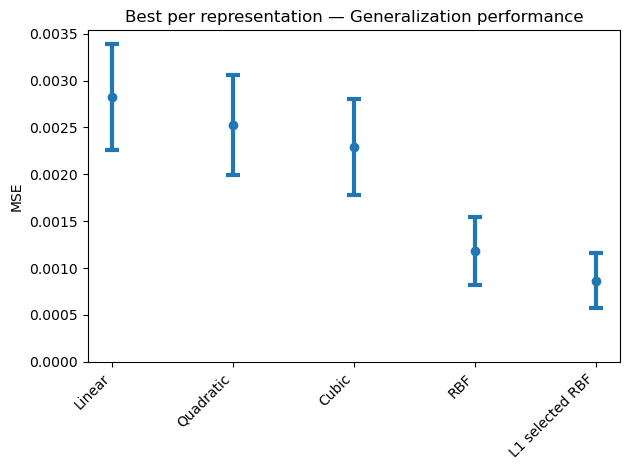

<Figure size 640x480 with 0 Axes>

In [39]:
plot_generalization_perf_per_repr(scores, squared_error)

## [Fashion-MNIST dataset](https://www.kaggle.com/datasets/zalando-research/fashionmnist) with different representations

The fashion-MNIST dataset is a dataset from Zalando's article images.
The inputs correspond to a flattened 28x28 (784 dimensions) grayscaled image, and the outputs correspond to apparel type.
The original dataset consists of 60K samples, but here we take only 500 samples (50 per class) and compress them into 10x10 (100 dimensions) grayscaled images.

We compare a linear representation, quadratic representation, cubic representation, and RBF kernels with random prototypes.
We first split the data into 80/20 training/test sets.
We then run internal RRS cross-validation with `k_internal=10` and `internal_train_frac=0.9`.

In [27]:
def construct_configs(epochs: int=3, batch_size: int=64, lr: float=1e-2) -> Dict:
    configurations = {}

    lambdas = [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1]

    # Populate polynomial up to degree 3
    for deg in np.arange(1, 4):
        config_name = "polynomial-deg_{}-unregularized".format(
            deg,
        )
        configurations[config_name] = {
            "model": partial(
                MultinomialLogisticGLM,
                grad_regularizer=grad_no_reg,
            ),
            "optimizer": SGD(lr),
            "feature_map": PolynomialFeatures(degree=deg),
            "epochs": epochs,
            "batch_size": batch_size,
        }
        for (reg_name, grad_regularizer) in [
            ("$\\ell_1$", grad_l1_reg),
            ("$\\ell_2$", grad_l2_reg),
        ]:
            for lambda_ in lambdas:
                config_name = "polynomial-deg_{}-reg_{}-λ_{}".format(
                    deg,
                    reg_name,
                    lambda_
                )
                configurations[config_name] = {
                    "model": partial(
                        MultinomialLogisticGLM,
                        grad_regularizer=grad_regularizer,
                        lambda_=lambda_,
                    ),
                    "optimizer": SGD(lr),
                    "feature_map": PolynomialFeatures(degree=deg),
                    "epochs": epochs,
                    "batch_size": batch_size,
                }

    # Populate RBF
    for (p, sigma) in [
        (10, 1.0),
        (10, 3.0),
        (50, 3.0),
        (100, 3.0),
    ]:
        config_name = "rbf-p_{}-sigma_{}-unregularized".format(
            p,
            sigma,
        )
        configurations[config_name] = {
            "model": partial(
                MultinomialLogisticGLM,
                grad_regularizer=grad_no_reg,
            ),
            "optimizer": SGD(lr),
            "feature_map": RadialBasisFunctionFeatures(p=p, sigma=sigma, seed=42),
            "epochs": epochs,
            "batch_size": batch_size,
        }
        for (reg_name, grad_regularizer) in [
            ("$\\ell_1$", grad_l1_reg),
            ("$\\ell_2$", grad_l2_reg),
        ]:
            for lambda_ in lambdas:
                config_name = "rbf-p_{}-sigma_{}-reg_{}-λ_{}".format(
                    p,
                    sigma,
                    reg_name,
                    lambda_
                )
                configurations[config_name] = {
                    "model": partial(
                        MultinomialLogisticGLM,
                        grad_regularizer=grad_regularizer,
                        lambda_=lambda_,
                    ),
                    "optimizer": SGD(lr),
                    "feature_map": RadialBasisFunctionFeatures(p=p, sigma=sigma, seed=42),
                    "epochs": epochs,
                    "batch_size": batch_size,
                }

    return configurations

def run_fashion_mnist(k_internal=10, seed=42, external_train_frac=0.7, internal_train_frac=0.9):
    X, y = load_fashion_mnist()
    X_tr, y_tr, X_te, y_te = split_data_rrs(seed, X, y, external_train_frac)
    
    configurations = construct_configs()

    exp = RRSInternalCV(configurations,
                        accuracy,
                        k_internal,
                        internal_train_frac,
                        seed,)
    
    exp = exp.fit(X_tr, y_tr, out_dim=10)
    scores = exp.evaluate(X_te, y_te)
    return scores

scores_2 = run_fashion_mnist()
    

  0%|          | 0/10 [00:00<?, ?it/s]

Training best model for representation deg_1: polynomial-deg_1-reg_$\ell_2$-λ_1e-05 (internal score: 0.08571428571428572)
Training best model for representation deg_2: polynomial-deg_2-reg_$\ell_2$-λ_0.003 (internal score: 0.08571428571428572)
Training best model for representation deg_3: polynomial-deg_3-reg_$\ell_2$-λ_1e-05 (internal score: 0.08571428571428572)
Training best model for representation rbf: rbf-p_50-sigma_3.0-unregularized (internal score: 0.08714285714285713)


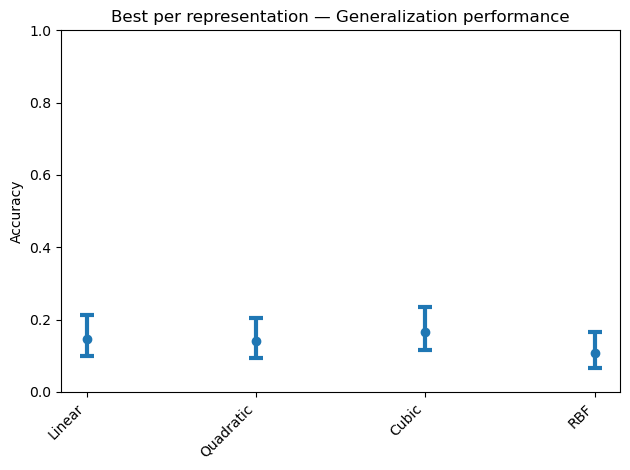

In [28]:
plot_generalization_perf_per_repr(scores_2, accuracy)